# EDA

План:
1. Качество данных
2. Динамика цен и распределение доходностей
3. Волатильность во времени
4. Корреляции
5. Традиционные рынки
6. Капитализация и ликвидность
7. Индикаторы и предсказуемость
8. Выводы для портфеля

In [351]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, PercentFormatter

DATA = "data/processed"

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "figure.dpi": 110,
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#b5b4ae",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "lines.linewidth": 1.6,
    "legend.frameon": False,
})
pd.set_option("display.precision", 3)

# подписи лог-осей обычными числами: 20 000, 50 000, 100 000
plain = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))


def log_axis(ax, which="y"):
    axis = ax.yaxis if which == "y" else ax.xaxis
    axis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    axis.set_major_formatter(plain)
    axis.set_minor_formatter(FuncFormatter(lambda v, _: ""))

## 1. Качество данных

Основной источник данных Binance: дневные цены закрытия в USDT (стейблкоин, курс которого привязан к 1 $), объёмы и лог-доходности. Таблицы взяты из `filled/`, пропуски в них уже заполнены.

Везде дальше доходность монеты за день $r_t = \ln(P_t / P_{t-1})$: на сколько цена закрытия дня изменилась относительно закрытия предыдущего дня, в логарифме. Для небольших движений это почти обычный процент, 0,01 ≈ +1%. Для больших разница заметна: 0,69 означает рост в 2 раза, −0,69 падение в 2 раза. Пример: цена выросла на 50%, потом упала на 50%, и из 1 $ осталось 0,75 $. Среднее обычных доходностей при этом 0%, а сумма лог-доходностей ln 1,5 + ln 0,5 = −0,29 честно показывает потерю. Лог-доходность описывает темп сложного роста, обычная доходность то, что портфель зарабатывает за период. Все распределения, волатильности, корреляции и хвосты в ноутбуке считаются по лог-доходности, если не сказано иное.

In [352]:
p_filled = pd.read_parquet(f"{DATA}/filled/prices.parquet")
returns_filled = pd.read_parquet(f"{DATA}/filled/returns.parquet")

print(f"с {p_filled.index.min():%Y-%m-%d} по {p_filled.index.max():%Y-%m-%d}, {p_filled.shape[0]} дней × {p_filled.shape[1]} монет")
p_filled.tail(3)

с 2020-01-01 по 2026-10-30, 2495 дней × 20 монет


,BTC,ETH,BNB,XRP,ADA,SOL,DOGE,TRX,DOT,LTC,LINK,AVAX,POL,XLM,ATOM,UNI,ETC,BCH,FIL,NEAR
date,,,,,,,,,,,,,,,,,,,,
2026-10-28 00:00:00+00:00,81343.50,2359.68,759.85,1.326,0.206,102.44,0.080,0.330,1.012,59.25,11.819,9.006,0.092,0.172,1.646,7.251,7.59,289.2,0.915,4.734
2026-10-29 00:00:00+00:00,77991.89,2253.13,698.46,1.238,0.190,95.64,0.075,0.352,0.909,54.96,10.620,8.281,0.088,0.162,1.502,6.471,7.09,273.9,0.827,4.059
2026-10-30 00:00:00+00:00,77368.77,2245.54,704.42,1.257,0.195,96.38,0.076,0.327,0.975,56.02,11.465,8.553,0.095,0.171,1.552,7.161,7.23,294.1,0.870,4.297


### Покрытие

In [353]:
first_day = p_filled.notna().idxmax()
print(first_day[first_day > p_filled.index[0]].sort_values().dt.strftime("%Y-%m-%d").to_string())

SOL     2020-08-11
DOT     2020-08-18
UNI     2020-09-17
AVAX    2020-09-22
NEAR    2020-10-14
FIL     2020-10-15


Все 20 монет есть с 2020-10-15, с этой даты и начинается рабочий период. Обвал марта 2020 в него не попадает.

In [354]:
START, END = "2020-10-15", "2026-10-30"
work = p_filled.loc[START:END]
print(len(work), "дней, пропусков:", int(work.isna().sum().sum()))

2207 дней, пропусков: 0


### Сверка с Coin Metrics

Coin Metrics и CoinGecko это сервисы, которые собирают цены с многих бирж, поэтому расхождения с Binance в десятые доли процента нормальны.

In [355]:
cm_prices = pd.read_parquet(f"{DATA}/coinmetrics_prices.parquet").loc[START:END]
diff_cm = (cm_prices / work - 1).abs() * 100

pd.DataFrame({
    "median, %": diff_cm.median(),
    "p99, %": diff_cm.quantile(0.99),
    "дней > 2%": (diff_cm > 2).sum(),
}).sort_values("дней > 2%").round(2)

,"median, %","p99, %",дней > 2%
BTC,0.10,0.93,3
ETH,0.12,1.18,3
BNB,0.11,1.10,3
LINK,0.17,1.44,5
ADA,0.15,1.42,6
LTC,0.15,1.34,7
DOT,0.15,1.40,9
XRP,0.13,1.52,9
ATOM,0.16,1.71,10
BCH,0.14,1.45,10


Медианное расхождение 0,1–0,2%, цены Binance годятся как основные. Ниже две найденные ошибки в других источниках.

In [356]:
ohlcv = pd.read_parquet(f"{DATA}/binance_ohlcv.parquet")
etc = ohlcv[ohlcv["coin"] == "ETC"].set_index("date").loc["2021-01-09":"2021-01-13", ["high", "close"]]
etc["Coin Metrics"] = cm_prices.loc[etc.index, "ETC"]
print("ETC, январь 2021, USD:")
print(etc.round(2).to_string())

cg_prices = pd.read_parquet(f"{DATA}/coingecko_prices.parquet")
window = slice("2026-02-22", "2026-03-26")
pd.DataFrame({
    "CoinGecko к Binance, медиана %": ((cg_prices.loc[window] / work.loc[window] - 1) * 100).median(),
    "Coin Metrics к Binance, медиана %": ((cm_prices.loc[window] / work.loc[window] - 1) * 100).median(),
}).loc[["ATOM", "FIL", "LINK", "ADA", "UNI", "BTC"]].round(2)

ETC, январь 2021, USD:
                           high  close  Coin Metrics
date                                                
2021-01-09 00:00:00+00:00  8.08   7.76          7.87
2021-01-10 00:00:00+00:00  9.98   8.83         11.17
2021-01-11 00:00:00+00:00  8.88   7.22          8.93
2021-01-12 00:00:00+00:00  7.68   7.05          7.91
2021-01-13 00:00:00+00:00  7.67   7.60          9.12


,"CoinGecko к Binance, медиана %","Coin Metrics к Binance, медиана %"
ATOM,15.03,-0.02
FIL,11.07,-0.01
LINK,8.14,0.02
ADA,5.72,0.02
UNI,5.40,-0.00
BTC,-0.00,0.03


У Coin Metrics цена ETC 10–13 января 2021 года выше дневного максимума Binance, у CoinGecko в феврале–марте 2026 года цены пяти монет завышены на 5–15%. Капитализацию поэтому берём из Coin Metrics.

Набор из 20 монет выбран задним числом, среди монет, которые торгуются в 2026 году. Монеты, не дожившие до 2026 года, в него попасть не могли (ошибка выжившего, survivorship bias), поэтому бэктест (проверка стратегии на истории) завысит доходность, сильнее всего у стратегий с большой долей альткоинов (всех монет, кроме BTC).

In [357]:
prices = p_filled.loc[START:END]
returns = returns_filled.loc[START:END].iloc[1:]
volumes = pd.read_parquet(f"{DATA}/filled/volumes.parquet").loc[START:END]
COINS = list(prices.columns)

prices.shape, returns.shape, int(returns.isna().sum().sum())

((2207, 20), (2206, 20), 0)

## 2. Динамика цен и распределение доходностей

### Динамика цен

Рост цены каждой монеты за рабочий период, среднегодовой темп (CAGR), самая глубокая просадка (падение от предыдущего максимума) и насколько цена в конце периода ниже своего максимума.

In [358]:
years = (prices.index[-1] - prices.index[0]).days / 365.25
growth = prices.iloc[-1] / prices.iloc[0]
dynamics = pd.DataFrame({
    "рост, раз": growth,
    "CAGR, %": (growth ** (1 / years) - 1) * 100,
    "max DD, %": (prices / prices.cummax() - 1).min() * 100,
    "сейчас ниже максимума, %": (prices.iloc[-1] / prices.max() - 1) * 100,
}).sort_values("рост, раз")
print(f"выросли {(growth > 1).sum()} монет из {len(growth)}; max DD глубже −85% у {(dynamics['max DD, %'] < -85).sum()}; "
      f"сейчас ниже максимума больше чем на 75% у {(dynamics['сейчас ниже максимума, %'] < -75).sum()}")
dynamics.round(2)

выросли 17 монет из 20; max DD глубже −85% у 15; сейчас ниже максимума больше чем на 75% у 14


,"рост, раз","CAGR, %","max DD, %","сейчас ниже максимума, %"
FIL,0.01,-50.73,-99.67,-99.54
DOT,0.24,-21.16,-98.60,-98.19
ATOM,0.27,-19.54,-97.24,-96.49
LINK,1.07,1.07,-90.18,-78.07
BCH,1.12,1.92,-94.25,-81.00
LTC,1.13,2.06,-89.45,-85.55
ETC,1.36,5.17,-95.46,-94.60
ADA,1.83,10.52,-95.15,-93.42
AVAX,2.07,12.82,-95.63,-93.66
XLM,2.31,14.84,-90.34,-76.74


За шесть лет 17 монет из 20 выросли, а разброс огромный: SOL в 42 раза, DOGE в 29, BNB в 22, BTC в 6,7 раза, а FIL упал в 72 раза (первая цена FIL взята в день начала торгов на Binance, 62,5 $). Просадки глубокие у всех: от −70% у TRX до почти −100% у FIL, у 15 монет глубже −85%, и 14 монет в конце периода стоят больше чем на 75% ниже своего максимума. Это ещё одно проявление ошибки выжившего: в наборе есть монеты, которые выросли в десятки раз, а монет, которые за это время исчезли, в нём нет.

Портфельная теория Марковица подбирает веса портфеля по ожидаемым доходностям и ковариациям активов и измеряет риск дисперсией доходностей. Это оправдано, если распределение доходностей близко к нормальному. Ниже проверяем, насколько это так.

### Экстремальные дни

Десять самых больших по модулю дневных доходностей среди всех монет, рядом то же изменение в процентах и доходность в те же дни по Coin Metrics.

In [359]:
cm_returns = np.log(cm_prices / cm_prices.shift(1))

top = returns.stack().rename("Binance").to_frame()
top = top.loc[top["Binance"].abs().nlargest(10).index]
top["Coin Metrics"] = [cm_returns.loc[d, c] for d, c in top.index]
top["изменение, %"] = (np.exp(top["Binance"]) - 1) * 100
top.round(2)

,,Binance,Coin Metrics,"изменение, %"
date,,,,
2021-01-28 00:00:00+00:00,DOGE,1.59,1.41,392.41
2021-04-16 00:00:00+00:00,DOGE,0.70,0.75,100.40
2024-12-03 00:00:00+00:00,TRX,0.67,0.64,96.11
2021-01-02 00:00:00+00:00,DOGE,0.62,0.64,85.32
2025-11-07 00:00:00+00:00,FIL,0.58,0.57,79.19
2021-01-06 00:00:00+00:00,XLM,0.56,0.56,75.93
2022-11-09 00:00:00+00:00,SOL,-0.55,-0.55,-42.25
2023-07-13 00:00:00+00:00,XRP,0.55,0.55,73.10
2025-03-02 00:00:00+00:00,ADA,0.54,0.53,72.15


Все десять движений есть и в Coin Metrics. Среди них DOGE 28.01.2021 (рост в 5 раз за день), SOL 09.11.2022 (крах биржи FTX, −42%), XRP 23.12.2020 и 13.07.2023 (иск регулятора США SEC к компании Ripple и решение суда). Связь с событиями взята из новостей, в данных её нет. Эти дни реальны и остаются в данных.

### Описательная статистика

Статистика дневных доходностей $r_t$ по каждой монете за рабочий период. `mean` и `std` в процентах за день, `min` и `max` переведены в обычное изменение цены за день. `kurt` здесь избыточный эксцесс, у нормального распределения он равен 0.

Хвосты здесь это редкие дни с очень большим $|r_t|$. Их тяжесть описывает хвостовой индекс α: если $P(|r_t| > x) \sim x^{-\alpha}$, то чем меньше α, тем чаще бывают огромные движения. У нормального распределения хвосты лёгкие, α бесконечно. При α ≤ 4 выборочный эксцесс неустойчив и зависит от отдельных дней. При α ≤ 2 нет даже конечной дисперсии, и волатильность как мера риска теряет смысл.

α оценивается методом Хилла (Hill, 1975) по k = 50 крайним дням каждого хвоста, это около 2% наблюдений: $\hat\alpha = \left(\frac{1}{k}\sum_{i=1}^{k} \ln\frac{X_{(i)}}{X_{(k+1)}}\right)^{-1}$, где $X_{(1)} \ge X_{(2)} \ge \dots$ упорядоченные по убыванию падения (левый хвост) или росты (правый хвост).

In [360]:
def hill_alpha(x, k=50):
    x = np.sort(x[x > 0])[::-1]
    return 1 / np.mean(np.log(x[:k] / x[k]))


stats = pd.DataFrame({
    "mean, %": returns.mean() * 100,
    "std, %": returns.std() * 100,
    "skew": returns.skew(),
    "kurt": returns.kurt(),
    "α left": returns.apply(lambda x: hill_alpha(-x.values)),
    "α right": returns.apply(lambda x: hill_alpha(x.values)),
    "min, %": (np.exp(returns.min()) - 1) * 100,
    "max, %": (np.exp(returns.max()) - 1) * 100,
})
stats.sort_values("kurt").round(2)

,"mean, %","std, %",skew,kurt,α left,α right,"min, %","max, %"
BTC,0.09,2.99,-0.09,3.98,3.22,4.26,-15.38,19.54
NEAR,0.06,6.33,0.10,4.46,3.80,3.72,-36.52,42.20
ETH,0.08,4.02,-0.17,5.40,3.11,3.32,-27.74,26.33
LINK,0.00,5.14,-0.37,5.83,3.48,4.07,-38.39,33.35
UNI,0.04,5.73,0.61,6.92,3.70,3.05,-33.86,54.89
ATOM,-0.06,5.31,-0.27,7.27,3.41,2.97,-39.77,33.19
AVAX,0.03,5.81,0.31,8.41,3.33,3.14,-37.49,71.33
DOT,-0.07,5.10,-0.03,8.53,3.22,2.83,-38.31,36.61
SOL,0.17,5.76,-0.27,8.72,2.72,3.34,-42.25,36.30
LTC,0.01,4.47,-0.63,8.82,2.73,3.49,-36.75,30.15


In [361]:
# эксцесс без одного самого крайнего дня и чувствительность оценки Хилла к k
without_max = returns.apply(lambda x: x.drop(x.abs().idxmax()).kurt())
print("kurt без одного крайнего дня:", without_max.loc[["DOGE", "TRX", "BNB", "BTC"]].round(1).to_dict())
pd.DataFrame({
    f"k={k}": {f"{coin} {side}": hill_alpha(sign * returns[coin].values, k)
               for coin in ["BTC", "TRX", "DOGE"] for side, sign in [("left", -1), ("right", 1)]}
    for k in [30, 50, 100, 220]
}).round(2)

kurt без одного крайнего дня: {'DOGE': 20.7, 'TRX': 17.8, 'BNB': 13.8, 'BTC': 3.6}


,k=30,k=50,k=100,k=220
BTC left,3.37,3.22,2.70,2.13
BTC right,4.60,4.26,2.73,2.31
TRX left,2.71,2.25,2.00,1.61
TRX right,2.87,2.02,1.85,1.62
DOGE left,2.58,2.68,2.47,2.01
DOGE right,2.50,2.45,1.71,1.62


Эксцесс по монетам от 4 до 138 и держится на отдельных днях: без одного дня, 28.01.2021, у DOGE он падает со 138 до 21. Оценки α при k = 50 от 2,0 до 4,3, но заметно зависят от k (у правого хвоста BTC от 4,6 при k = 30 до 2,7 при k = 100). Вывод: хвосты тяжёлые, а у монет с α около 2,0–2,5 (TRX, XRP, XLM, ETC, BCH, FIL, DOGE, POL) нельзя исключить даже бесконечную дисперсию.

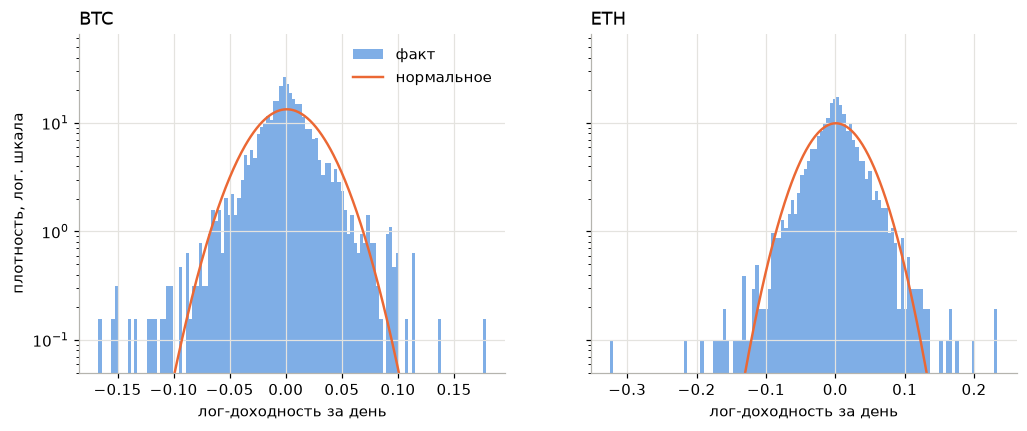

In [362]:
from statistics import NormalDist

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, coin in zip(axes, ["BTC", "ETH"]):
    r = returns[coin]
    ax.hist(r, bins=120, density=True, color=COLORS[0], alpha=0.6, label="факт")
    x = np.linspace(r.min(), r.max(), 400)
    ax.plot(x, [NormalDist(r.mean(), r.std()).pdf(v) for v in x], color=COLORS[1], label="нормальное")
    ax.set_yscale("log")
    ax.set_ylim(5e-2, None)
    ax.set_title(coin)
    ax.set_xlabel("лог-доходность за день")
axes[0].set_ylabel("плотность, лог. шкала")
axes[0].legend();

Гистограмма дневных доходностей BTC и ETH и нормальная плотность с теми же средним и std. Шкала по вертикали логарифмическая, чтобы были видны хвосты. В центре фактическое распределение выше и уже нормального, на краях заметно толще.

### Насколько часто бывают резкие дни

σ здесь std дневной доходности монеты за период. VaR 1% это убыток за день, хуже которого бывает только в 1% дней, CVaR 1% средний убыток в этих днях; в таблице оба в лог-доходности × 100, знак минус означает убыток.

In [363]:
z = (returns - returns.mean()) / returns.std()
q01 = returns.quantile(0.01)

tails = pd.DataFrame({
    "дней > 3σ": (z.abs() > 3).sum(),
    "доля > 3σ, %": (z.abs() > 3).mean() * 100,
    "VaR 1%, факт": q01 * 100,
    "VaR 1%, норм.": (returns.mean() + returns.std() * NormalDist().inv_cdf(0.01)) * 100,
    "CVaR 1%, факт": returns[returns.le(q01)].mean() * 100,
})
print(f"при нормальном распределении доля дней > 3σ равна 0,27%, это около {0.0027 * len(returns):.0f} дней за период")
tails.sort_values("доля > 3σ, %").round(2)

при нормальном распределении доля дней > 3σ равна 0,27%, это около 6 дней за период


,дней > 3σ,"доля > 3σ, %","VaR 1%, факт","VaR 1%, норм.","CVaR 1%, факт"
NEAR,25,1.13,-15.91,-14.67,-21.54
LINK,26,1.18,-14.22,-11.95,-18.81
DOGE,28,1.27,-13.86,-15.96,-22.55
UNI,31,1.41,-13.66,-13.29,-18.49
SOL,33,1.50,-14.01,-13.22,-21.72
DOT,33,1.50,-12.52,-11.93,-19.08
ETH,34,1.54,-11.30,-9.27,-15.22
FIL,34,1.54,-14.66,-13.79,-22.47
BNB,35,1.59,-10.27,-9.27,-15.82
BCH,35,1.59,-12.68,-11.32,-17.63


У каждой монеты 25–45 дней, когда доходность отклонялась от своего среднего больше чем на 3σ. При нормальном распределении таких дней было бы около 6.

VaR по нормальному распределению у 19 монет из 20 мягче фактического, а CVaR ещё на 3–9 п.п. (процентных пунктов) хуже VaR. Обе оценки опираются примерно на 22 дня и потому шумные: направление отличия от нормального распределения надёжно, его величина нет.

### Ошибка оценки среднего

Марковицу нужна ожидаемая доходность μ. Оценка по истории: среднее дневной доходности за период и его стандартная ошибка $\sigma/\sqrt{n}$, оба значения умножены на 365. Считаем по обеим доходностям: при высокой волатильности среднее лог-доходности заметно ниже среднего обычной (на $\sigma^2/2$, у крипты это десятки процентов в год), как в примере +50% и −50% из раздела 1.

лог-доходность: медиана среднего 14% в год, SE 40%, монет с |t| > 2: 0, max |t| 1.64
обычная доходность: монет с |t| > 2: 4 (SOL 2.73, BNB 2.52, TRX 2.17, BTC 2.06), порог с поправкой Бонферрони на 20 монет 3,02


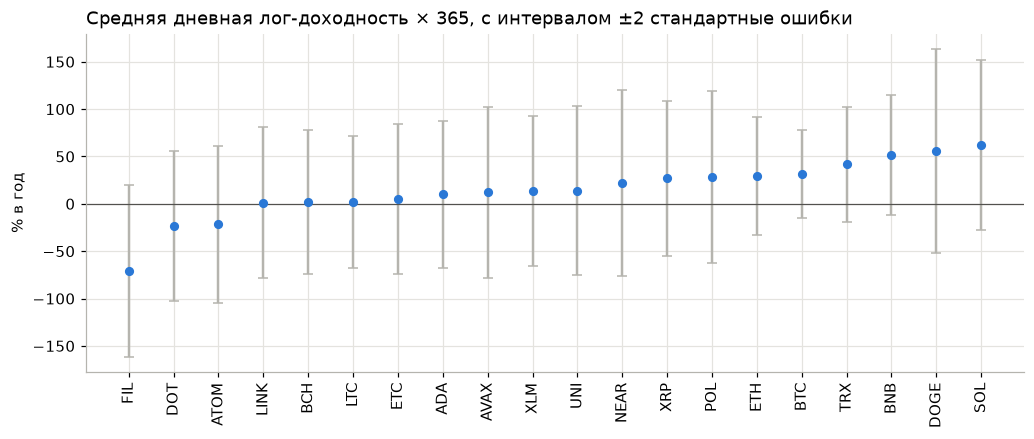

In [364]:
n = len(returns)
mu = returns.mean() * 365 * 100
se = returns.std() / np.sqrt(n) * 365 * 100
t_mu = mu / se
simple_r = np.expm1(returns)
t_simple = simple_r.mean() / (simple_r.std() / np.sqrt(n))
order_mu = mu.sort_values().index

fig, ax = plt.subplots(figsize=(11, 4))
ax.errorbar(range(len(order_mu)), mu[order_mu], yerr=2 * se[order_mu], fmt="o", ms=5, capsize=3, color=COLORS[0], ecolor="#b5b4ae")
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(range(len(order_mu)), order_mu, rotation=90)
ax.set_ylabel("% в год")
ax.set_title("Средняя дневная лог-доходность × 365, с интервалом ±2 стандартные ошибки")

print(f"лог-доходность: медиана среднего {mu.median():.0f}% в год, SE {se.median():.0f}%, монет с |t| > 2: {(t_mu.abs() > 2).sum()}, max |t| {t_mu.abs().max():.2f}")
big = t_simple[t_simple.abs() > 2].sort_values(ascending=False)
print(f"обычная доходность: монет с |t| > 2: {len(big)} ({', '.join(f'{c} {v:.2f}' for c, v in big.items())}), порог с поправкой Бонферрони на 20 монет 3,02")

По лог-доходности ни у одной монеты среднее не отличается от нуля на уровне |t| > 2, у типичной монеты стандартная ошибка больше самой оценки. По обычной доходности |t| чуть выше 2 у четырёх монет, но поправку на 20 одновременных проверок не проходит ни одна, а сами эти монеты попали в набор как выжившие. Оптимизатор, который получает такие μ, подбирает веса под шум. Это главный аргумент за методы, которым μ не нужна.

## 3. Волатильность во времени

Волатильность здесь это стандартное отклонение дневных доходностей $r_t$. На графике оно посчитано в скользящем окне 30 дней и умножено на √365, чтобы получить годовое значение.

BTC: от 17% (2023-08) до 121% (2021-06)
медиана: от 32% (2023-09) до 252% (2021-05)


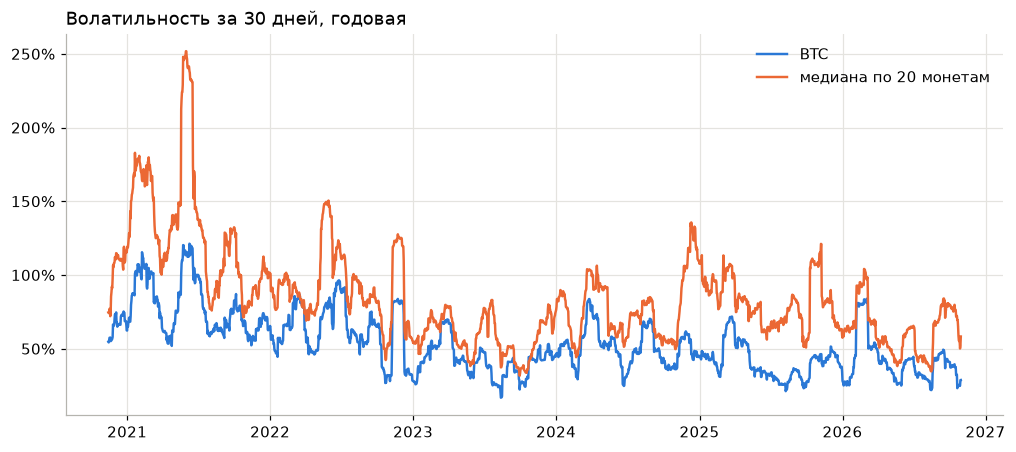

In [365]:
vol30 = returns.rolling(30).std() * np.sqrt(365)

fig, ax = plt.subplots()
ax.plot(vol30["BTC"], label="BTC")
ax.plot(vol30.median(axis=1), label="медиана по 20 монетам")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Волатильность за 30 дней, годовая")
ax.legend(loc="upper right")

for name, s in [("BTC", vol30["BTC"]), ("медиана", vol30.median(axis=1))]:
    print(f"{name}: от {s.min():.0%} ({s.idxmin():%Y-%m}) до {s.max():.0%} ({s.idxmax():%Y-%m})")

От минимума до максимума волатильность меняется в 7 раз у BTC (с 17% до 121%) и в 8 раз у медианной монеты.

### Кластеризация

Автокорреляция дневных доходностей $r_t$ и их модулей $|r_t|$: насколько сегодняшнее значение связано со значением k дней назад.

лаг 1: r -0.038, |r| 0.232; лаг 60: |r| 0.041; полоса ±0.043
Льюнг–Бокс, 20 лагов, медиана по монетам: r 39, r устойчивый 22 (выше 31.41: 1 из 20), |r| 859; критическое значение 31.41
corr(log vol месяца, следующего месяца): 0.50


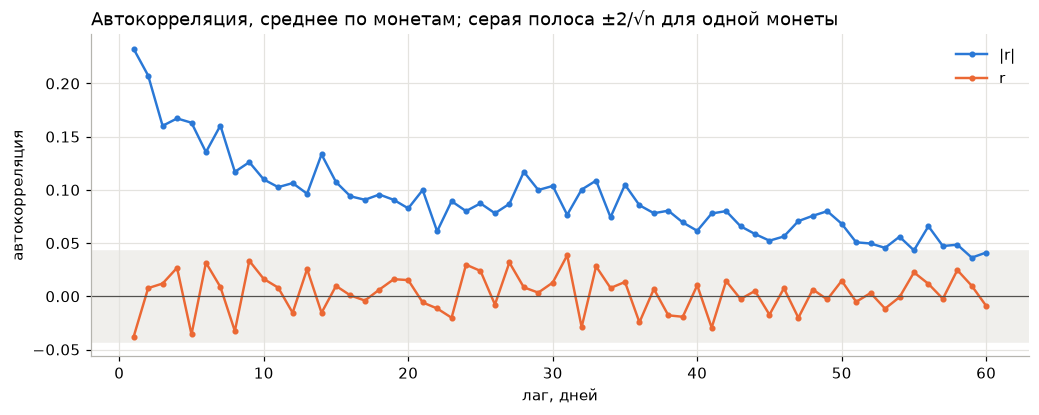

In [366]:
lags = range(1, 61)
acf_r = [returns.apply(lambda x: x.autocorr(l)).mean() for l in lags]
acf_abs = [returns.abs().apply(lambda x: x.autocorr(l)).mean() for l in lags]
band = 2 / np.sqrt(len(returns))
print(f"лаг 1: r {acf_r[0]:.3f}, |r| {acf_abs[0]:.3f}; лаг 60: |r| {acf_abs[-1]:.3f}; полоса ±{band:.3f}")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(lags, acf_abs, marker="o", ms=3, label="|r|")
ax.plot(lags, acf_r, marker="o", ms=3, label="r")
ax.axhline(0, color="#52514e", lw=0.8)
ax.axhspan(-band, band, color="#f0efec", zorder=0)
ax.set_xlabel("лаг, дней")
ax.set_ylabel("автокорреляция")
ax.set_title("Автокорреляция, среднее по монетам; серая полоса ±2/√n для одной монеты")
ax.legend()


def ljung_box(x, lags=20):
    n = len(x)
    return n * (n + 2) * sum(x.autocorr(k) ** 2 / (n - k) for k in range(1, lags + 1))


def ljung_box_robust(x, lags=20):
    # версия, устойчивая к гетероскедастичности: ρ_k² делится на Σx_t²x_{t−k}² / (Σx_t²)²
    x = (x - x.mean()).values
    q = 0.0
    for k in range(1, lags + 1):
        rho = np.sum(x[k:] * x[:-k]) / np.sum(x ** 2)
        tau = np.sum(x[k:] ** 2 * x[:-k] ** 2) / np.sum(x ** 2) ** 2
        q += rho ** 2 / tau
    return q


CRIT_20 = 31.41   # χ² с 20 степенями свободы, уровень 5%
lb = pd.DataFrame({"r": returns.apply(ljung_box), "r, устойчивый": returns.apply(ljung_box_robust), "|r|": returns.abs().apply(ljung_box)})
print(f"Льюнг–Бокс, 20 лагов, медиана по монетам: r {lb['r'].median():.0f}, r устойчивый {lb['r, устойчивый'].median():.0f} "
      f"(выше {CRIT_20}: {(lb['r, устойчивый'] > CRIT_20).sum()} из 20), |r| {lb['|r|'].median():.0f}; критическое значение {CRIT_20}")
n30 = len(returns) // 30 * 30
vol_month = np.log(returns.iloc[:n30].groupby(np.arange(n30) // 30).std())
print(f"corr(log vol месяца, следующего месяца): {vol_month.apply(lambda x: x.autocorr(1)).median():.2f}")

Тест Льюнга–Бокса проверяет, связаны ли значения ряда с прошлыми. Обычная версия для доходностей формально значима (39 при пороге 31,4), но она рассчитана на постоянную дисперсию и при меняющейся волатильности ошибается в сторону значимости. Устойчивая версия значима только у одной монеты из 20: по прошлым доходностям будущие не предсказываются.

Модули доходностей связаны с прошлыми сильно: 0,23 на первом лаге против −0,04 у самих доходностей, и связь держится около двух месяцев. Бурные дни идут сериями, волатильность соседних 30-дневных блоков коррелирует на 0,50, то есть она хорошо прогнозируется по своей истории.

### Доходность в бурные и спокойные периоды

Если волатильность прогнозируется, можно уменьшать вложения в крипту в бурные периоды, держа часть денег вне её (для этого нужна денежная позиция, раздел 8). Это выгодно, только если в бурные периоды доходность на единицу риска хуже. Делим дни на три равные группы по волатильности портфеля 1/N (равные доли во все 20 монет) за предыдущие 30 дней, известной на начало дня, и считаем в каждой группе Шарп 1/N, то есть среднюю доходность, делённую на её std, в годовом выражении.

In [367]:
ew_simple = np.expm1(returns).mean(axis=1)
past_vol = np.log1p(ew_simple).rolling(30).std().shift(1)
group = pd.qcut(past_vol, 3, labels=["низкая", "средняя", "высокая"])
by_vol = ew_simple.groupby(group, observed=True)
sharpe_d = by_vol.apply(lambda x: x.mean() / x.std())
pd.DataFrame({
    "дней": by_vol.size(),
    "Sharpe 1/N, в год": sharpe_d * np.sqrt(365),
    "SE Sharpe": np.sqrt((1 + sharpe_d ** 2 / 2) / by_vol.size()) * np.sqrt(365),
}).T.round(2)

,низкая,средняя,высокая
дней,726.00,725.00,725.00
"Sharpe 1/N, в год",0.75,0.64,1.13
SE Sharpe,0.71,0.71,0.71


Шарп в бурные периоды 1,13, в спокойные 0,75. Стандартная ошибка Шарпа в каждой группе около 0,7, так что разница незначима, но признаков того, что в бурные периоды доходность на единицу риска хуже, нет. Значит, на прирост Шарпа от сокращения доли крипты в бурные периоды рассчитывать не стоит. Прогноз волатильности здесь полезен прежде всего для распределения риска между монетами.

### Относительно BTC

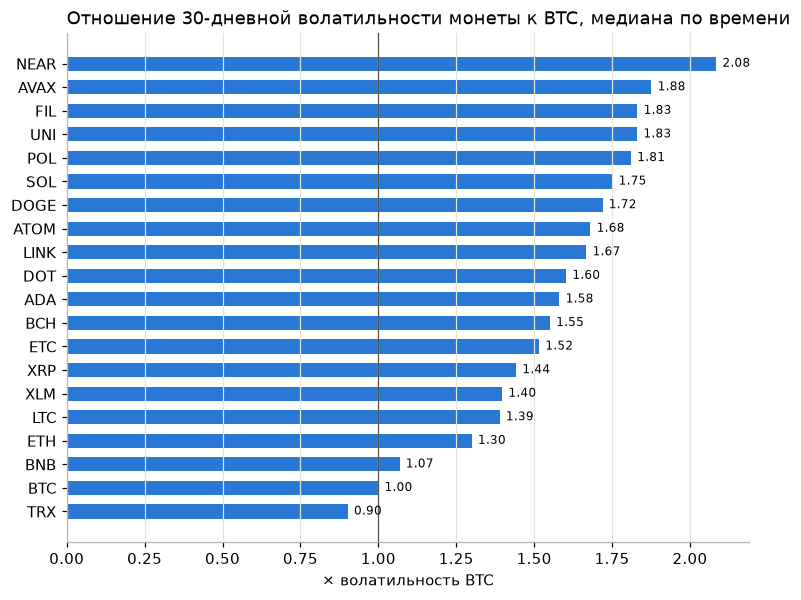

In [368]:
rel = vol30.div(vol30["BTC"], axis=0).median().sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(rel.index, rel.values, height=0.6)
ax.axvline(1, color="#52514e", lw=0.8)
for i, v in enumerate(rel.values):
    ax.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("× волатильность BTC")
ax.set_title("Отношение 30-дневной волатильности монеты к BTC, медиана по времени")
ax.grid(axis="y", visible=False);

Большинство альткоинов в 1,3–2,1 раза волатильнее BTC, BNB на уровне BTC, ниже только TRX. Самые волатильные NEAR, AVAX, FIL и UNI.

## 4. Корреляции

Корреляции Пирсона между дневными доходностями $r_t$ разных монет за весь рабочий период.

по парам: среднее 0.59, мин 0.36, макс 0.82


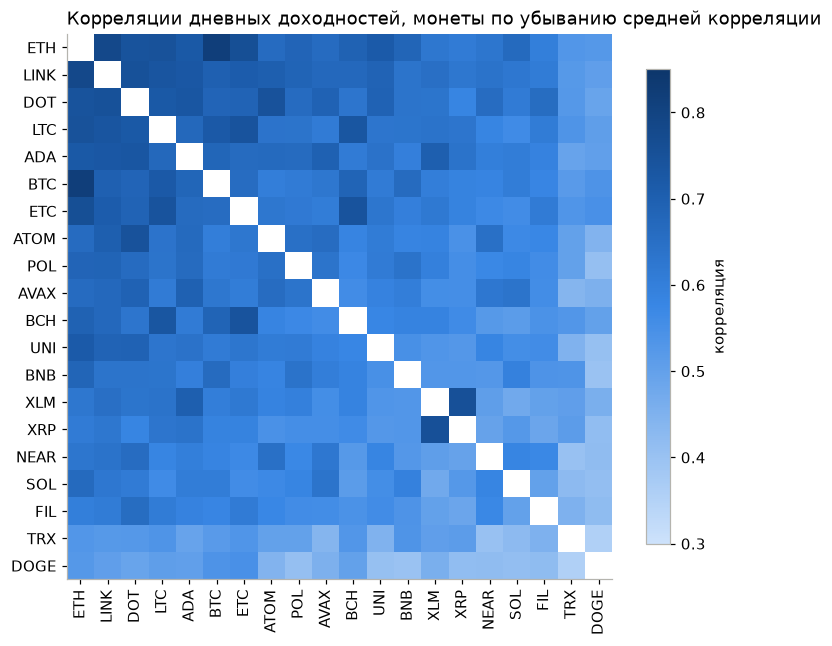

In [369]:
from matplotlib.colors import LinearSegmentedColormap

blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
corr = returns.corr()
order = corr.mean().sort_values(ascending=False).index
iu = np.triu_indices(len(corr), k=1)

shown = corr.loc[order, order].mask(np.eye(len(order), dtype=bool))   # диагональ = 1 скрыта
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(shown, cmap=blues, vmin=0.3, vmax=0.85)
ax.set_xticks(range(len(order)), order, rotation=90)
ax.set_yticks(range(len(order)), order)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="корреляция")
ax.set_title("Корреляции дневных доходностей, монеты по убыванию средней корреляции")

pairs = corr.values[iu]
print(f"по парам: среднее {pairs.mean():.2f}, мин {pairs.min():.2f}, макс {pairs.max():.2f}")

Все пары коррелированы положительно, от 0,36 до 0,82. Сильнее всего связаны ETH, LINK, DOT, LTC, ADA и BTC, слабее всего DOGE и TRX.

### Во времени

Средняя корреляция по парам в окне 90 дней.

от 0.33 (2021-04) до 0.86 (2021-08)


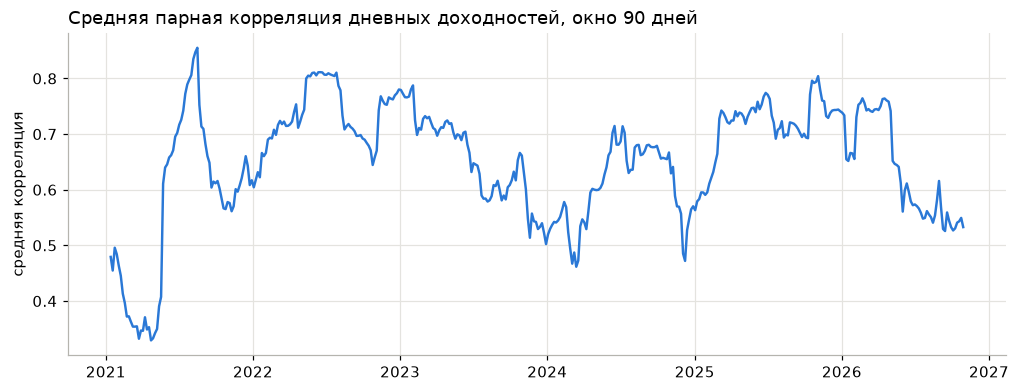

In [370]:
def mean_corr(df):
    return df.corr().values[iu].mean()

roll_corr = pd.Series({returns.index[i - 1]: mean_corr(returns.iloc[i - 90:i]) for i in range(90, len(returns) + 1, 5)})

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(roll_corr)
ax.set_ylabel("средняя корреляция")
ax.set_title("Средняя парная корреляция дневных доходностей, окно 90 дней")
print(f"от {roll_corr.min():.2f} ({roll_corr.idxmin():%Y-%m}) до {roll_corr.max():.2f} ({roll_corr.idxmax():%Y-%m})")

Средняя корреляция менялась от 0,33 (окно, закончившееся в апреле 2021, когда монеты росли каждая по-своему) до 0,86 (окно май–август 2021 с обвалом 19 мая).

### В сильные дни BTC

In [371]:
btc = returns["BTC"]

# та же корреляционная матрица без асимметрии: сколько даёт сам отбор крайних дней
rng = np.random.default_rng(0)
gauss = rng.standard_normal((200_000, len(COINS))) @ np.linalg.cholesky(corr.values).T
student = gauss / np.sqrt(rng.chisquare(4, size=(200_000, 1)) / 4)   # многомерное t, ν = 4


def tails_corr(df, key):
    return {"10% худших дней BTC": mean_corr(df[df[key] <= df[key].quantile(0.1)]),
            "10% лучших дней BTC": mean_corr(df[df[key] >= df[key].quantile(0.9)])}


stress = pd.DataFrame({
    "факт": tails_corr(returns, "BTC"),
    "нормальная модель": tails_corr(pd.DataFrame(gauss, columns=COINS), "BTC"),
    "t-модель, ν = 4": tails_corr(pd.DataFrame(student, columns=COINS), "BTC"),
})
stress.loc["разница худшие − лучшие"] = stress.iloc[0] - stress.iloc[1]
stress.round(2)

,факт,нормальная модель,"t-модель, ν = 4"
10% худших дней BTC,0.62,0.38,0.45
10% лучших дней BTC,0.34,0.39,0.47
разница худшие − лучшие,0.28,-0.00,-0.01


Сравнивать эти числа с общей корреляцией 0,59 нельзя: если отобрать дни, когда BTC сильно двигался, измеренная корреляция меняется даже у данных без всякой асимметрии. Это видно по двум моделям с той же матрицей корреляций и симметричными хвостами, у них худшие и лучшие дни дают одно и то же. В данных разница большая: в дни резкого падения BTC корреляция 0,62, в дни резкого роста 0,34. В падения монеты движутся заметно синхроннее, и диверсификация внутри крипты в эти дни слабеет.

### Сколько независимых факторов

In [372]:
eig, vec = np.linalg.eigh(corr)
eig, vec = eig[::-1], vec[:, ::-1]
share = eig / eig.sum()
print("доля дисперсии, первые 4 компоненты:", np.round(share[:4], 3))

# сколько даёт модель «один общий фактор + независимый шум» с теми же нагрузками
load = np.sqrt(eig[0]) * vec[:, 0]
rng = np.random.default_rng(1)
lam2 = []
for _ in range(200):
    x = rng.standard_normal((len(returns), 1)) * load + rng.standard_normal((len(returns), len(COINS))) * np.sqrt(1 - load ** 2)
    lam2.append(np.linalg.eigvalsh(np.corrcoef(x.T))[-2])
print(f"второе собственное число: факт {eig[1]:.2f}, модель с одним фактором: максимум за 200 прогонов {max(lam2):.2f}")
pc2 = pd.Series(vec[:, 1], index=COINS).sort_values()
print("вторая компонента, края:", ", ".join(pc2.index[:5]), "против", ", ".join(pc2.index[-5:]))

# корреляции, которые остаются после вычитания общего движения рынка
market = returns.mean(axis=1)
resid = returns.apply(lambda x: x - x.cov(market) / market.var() * market)
rc = resid.corr().where(np.triu(np.ones((len(COINS), len(COINS)), dtype=bool), 1)).stack().sort_values(ascending=False)
print("самые сильные остаточные корреляции:", ", ".join(f"{a}–{b} {v:.2f}" for (a, b), v in rc.head(4).items()))

доля дисперсии, первые 4 компоненты: [0.62  0.042 0.036 0.033]


второе собственное число: факт 0.84, модель с одним фактором: максимум за 200 прогонов 0.68
вторая компонента, края: NEAR, SOL, AVAX, ATOM, UNI против BCH, DOGE, XRP, XLM, TRX
самые сильные остаточные корреляции: XRP–XLM 0.42, BTC–ETH 0.35, ETC–BCH 0.26, LTC–BCH 0.22


Главные компоненты это независимые направления движения, на которые раскладываются доходности 20 монет. Первая, общее движение рынка, объясняет 62% колебаний. Остальное не случайный шум: вторая компонента (4%) выше, чем бывает в модели с одним общим фактором, и делит монеты на две группы, давние (XRP, XLM, TRX, DOGE, BCH, LTC, ETC) и молодые (NEAR, SOL, AVAX, ATOM, UNI). После вычитания общего движения остаются заметные пары: XRP и XLM, BTC и ETH, BCH с ETC и LTC.

### Зависимость от BTC

In [373]:
beta_btc = returns.apply(lambda x: x.cov(btc) / btc.var())
down, up = btc < 0, btc > 0
beta_down = returns[down].apply(lambda x: x.cov(btc[down]) / btc[down].var())
beta_up = returns[up].apply(lambda x: x.cov(btc[up]) / btc[up].var())
print(f"медиана беты альткоинов: все дни {beta_btc.drop('BTC').median():.2f}, дни падения BTC {beta_down.drop('BTC').median():.2f}, дни роста {beta_up.drop('BTC').median():.2f}")
pd.DataFrame({"бета": beta_btc, "R²": corr["BTC"] ** 2}).drop("BTC").sort_values("бета").round(2).T

медиана беты альткоинов: все дни 1.13, дни падения BTC 1.32, дни роста 0.83


,TRX,BNB,XLM,XRP,ATOM,LTC,ETH,BCH,ETC,ADA,FIL,SOL,DOT,UNI,POL,LINK,AVAX,NEAR,DOGE
бета,0.67,0.90,1.03,1.03,1.07,1.08,1.10,1.12,1.13,1.13,1.13,1.17,1.17,1.17,1.20,1.20,1.21,1.23,1.24
R²,0.27,0.44,0.36,0.34,0.36,0.52,0.67,0.47,0.44,0.46,0.33,0.37,0.47,0.37,0.37,0.49,0.39,0.34,0.29


Бета показывает, на сколько в среднем меняется монета, когда BTC меняется на 1%. У альткоинов, кроме TRX и BNB, бета от 1,03 до 1,24, то есть они двигаются на 1–1,2%. BTC объясняет 29–67% дисперсии альткоинов, у TRX 27%. Бета по всему периоду усредняет разные дни: в дни падения BTC медианная бета альткоинов 1,32, в дни роста 0,83.

### Режимы рынка

Бычья фаза, когда цена BTC выше своей средней за 200 дней (SMA200), иначе медвежья. Фаза дня определяется по закрытию предыдущего дня: иначе в неё попадает доходность того же дня, которая сама и переводит цену через среднюю. Портфель 1/N держит равные доли и ребалансируется каждый день, то есть доли каждый день возвращаются к равным. Темп роста это годовой темп, с которым рос бы капитал, если бы фаза длилась год.

смен фазы: 52; t разницы доходности 1/N: 1.52
SMA100: t разницы 2.65, корреляция 0.50 и 0.74
SMA300: t разницы 1.26, корреляция 0.56 и 0.71
корреляция бычья / медвежья внутри лет: 2021: 0.48 / 0.79, 2023: 0.58 / 0.56, 2024: 0.56 / 0.68, 2025: 0.73 / 0.69, 2026: 0.54 / 0.65


,дней,"1/N, темп % в год","BTC, темп % в год",средняя корреляция
бычья,1262,116.31,74.34,0.53
медвежья,944,-17.22,-0.62,0.72


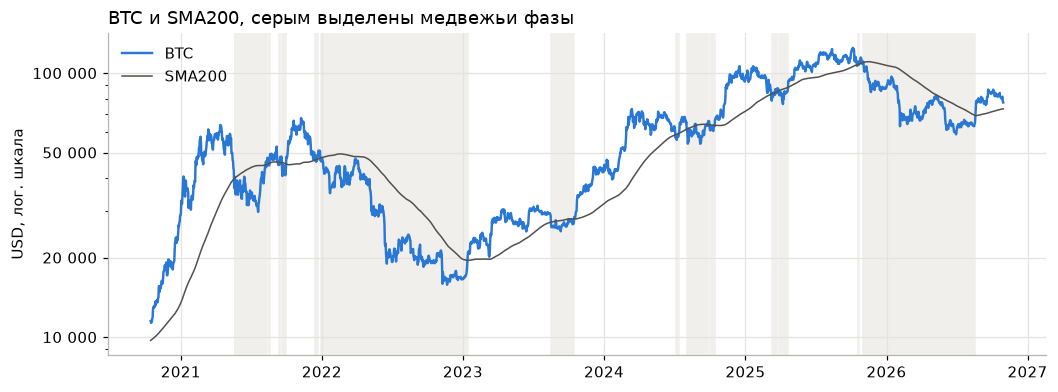

In [374]:
simple = np.exp(returns) - 1
ew = np.log1p(simple.mean(axis=1))   # 1/N, ребалансировка каждый день


def phase(window):
    # (бычьи дни, медвежьи дни) по закрытию предыдущего дня; дни, где средняя ещё не набралась, не входят никуда
    sma = p_filled["BTC"].rolling(window).mean()
    above = (p_filled["BTC"] > sma).shift(1).reindex(returns.index).astype(bool)
    valid = sma.shift(1).reindex(returns.index).notna()
    return above & valid, ~above & valid


bull, bear = phase(200)
sma200 = p_filled["BTC"].rolling(200).mean().loc[START:END]

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(prices["BTC"], color=COLORS[0], label="BTC")
ax.plot(sma200, color="#52514e", lw=1, label="SMA200")
ax.fill_between(returns.index, 0, 1, where=bear, transform=ax.get_xaxis_transform(), color="#f0efec", zorder=0)
ax.set_yscale("log")
log_axis(ax)
ax.set_ylabel("USD, лог. шкала")
ax.set_title("BTC и SMA200, серым выделены медвежьи фазы")
ax.legend(loc="upper left")

def t_diff(a, b):
    return (a.mean() - b.mean()) / np.sqrt(a.var() / len(a) + b.var() / len(b))


rows = {}
for name, m in [("бычья", bull), ("медвежья", bear)]:
    rows[name] = {
        "дней": int(m.sum()),
        "1/N, темп % в год": (np.exp(ew[m].mean() * 365) - 1) * 100,
        "BTC, темп % в год": (np.exp(returns.loc[m, "BTC"].mean() * 365) - 1) * 100,
        "средняя корреляция": mean_corr(returns[m]),
    }
print(f"смен фазы: {int((bull != bull.shift()).sum() - 1)}; t разницы доходности 1/N: {t_diff(ew[bull], ew[bear]):.2f}")
for window in [100, 300]:
    b, br = phase(window)
    print(f"SMA{window}: t разницы {t_diff(ew[b], ew[br]):.2f}, корреляция {mean_corr(returns[b]):.2f} и {mean_corr(returns[br]):.2f}")
yearly = {y: (mean_corr(returns[bull & (returns.index.year == y)]), mean_corr(returns[bear & (returns.index.year == y)]))
          for y in range(2021, 2027) if min((bull & (returns.index.year == y)).sum(), (bear & (returns.index.year == y)).sum()) > 30}
print("корреляция бычья / медвежья внутри лет:", ", ".join(f"{y}: {a:.2f} / {b:.2f}" for y, (a, b) in yearly.items()))
pd.DataFrame(rows).T.round(2).astype({"дней": int})

В бычьей фазе 1/N рос в темпе +116% в год, в медвежьей терял 17% в год, но разница незначима (t = 1,5) и сильно зависит от окна средней. Корреляция монет в медвежьей фазе выше (0,72 против 0,53) при любом окне, но внутри отдельных лет так не всегда, и заметную часть разницы даёт контраст 2021 и 2022 годов. Фазы полезны, чтобы разбить результаты бэктеста по периодам; надёжным сигналом они не являются.

## 5. Традиционные рынки

Индексы не торгуются в выходные, поэтому здесь доходности недельные: логарифм отношения цены закрытия пятницы к закрытию предыдущей пятницы. Крипта взята на закрытие пятницы (24:00 UTC), индексы на закрытие торгов в Нью-Йорке. Сравниваем с индексами акций США (S&P 500, технологический NASDAQ, малые компании RUT), золотом, индексом доллара DXY, индексом ожидаемой волатильности S&P 500 VIX и доходностью 10-летних облигаций США UST10Y. VIX и UST10Y это уровни показателей, для них берутся изменения за неделю.

In [375]:
indices = pd.read_parquet(f"{DATA}/filled/indices.parquet").loc[START:END]
w_crypto = prices.resample("W-FRI").last()
w_idx = indices.resample("W-FRI").last()

wr = np.log(w_crypto).diff()
wr["EW"] = ew.resample("W-FRI").sum()   # 1/N с ежедневной ребалансировкой, доходность за неделю
macro = np.log(w_idx[["SPX", "NASDAQ", "RUT", "GOLD", "DXY"]]).diff()
macro["ΔVIX"] = w_idx["VIX"].diff()
macro["ΔUST10Y"] = w_idx["UST10Y"].diff()

weekly = pd.concat([wr, macro], axis=1).dropna()
MACRO = list(macro.columns)
print(len(weekly), "недель")

315 недель


In [376]:
alts = [c for c in COINS if c != "BTC"]
c = weekly.corr()
table = c.loc[["BTC", "ETH", "EW"], MACRO]
table.loc["медиана альткоинов"] = c.loc[alts, MACRO].median()
table.rename(index={"EW": "1/N"}).round(2)

,SPX,NASDAQ,RUT,GOLD,DXY,ΔVIX,ΔUST10Y
BTC,0.27,0.30,0.32,0.08,-0.14,-0.23,0.05
ETH,0.34,0.36,0.38,0.03,-0.16,-0.30,-0.00
1/N,0.31,0.32,0.36,0.04,-0.15,-0.25,-0.01
медиана альткоинов,0.25,0.27,0.30,0.03,-0.12,-0.21,-0.01


Корреляция недельных доходностей с акциями 0,25–0,38, с золотом около нуля. С изменением VIX корреляция от −0,21 до −0,30: когда фондовый рынок нервничает, крипта падает, как другие рискованные активы. С индексом доллара DXY связь слабее (−0,12…−0,16), чуть выше порога значимости, который при 315 неделях около ±0,11.

### Бенчмарки

In [377]:
def perf(log_r, periods_per_year=365.25 / 7):
    # CAGR и просадка по накопленной стоимости; vol и Sharpe по обычным доходностям, безрисковая ставка 0
    value = np.exp(log_r.cumsum())
    r = np.expm1(log_r)
    sharpe_p = r.mean() / r.std()
    return pd.Series({
        "CAGR, %": (value.iloc[-1] ** (periods_per_year / len(log_r)) - 1) * 100,
        "vol, %": r.std() * np.sqrt(periods_per_year) * 100,
        "Sharpe": sharpe_p * np.sqrt(periods_per_year),
        "SE Sharpe": np.sqrt((1 + sharpe_p ** 2 / 2) / len(r)) * np.sqrt(periods_per_year),
        "max DD, %": (value / value.cummax() - 1).min() * 100,
    })


BENCH = ["BTC", "EW", "SPX", "NASDAQ", "GOLD"]
weekly[BENCH].apply(perf).T.rename(index={"EW": "1/N"}).round(2)

,"CAGR, %","vol, %",Sharpe,SE Sharpe,"max DD, %"
BTC,37.49,59.62,0.83,0.41,-74.23
1/N,44.74,77.01,0.85,0.41,-77.83
SPX,13.74,15.93,0.89,0.41,-24.82
NASDAQ,13.77,20.86,0.72,0.41,-35.72
GOLD,12.58,16.99,0.78,0.41,-25.71


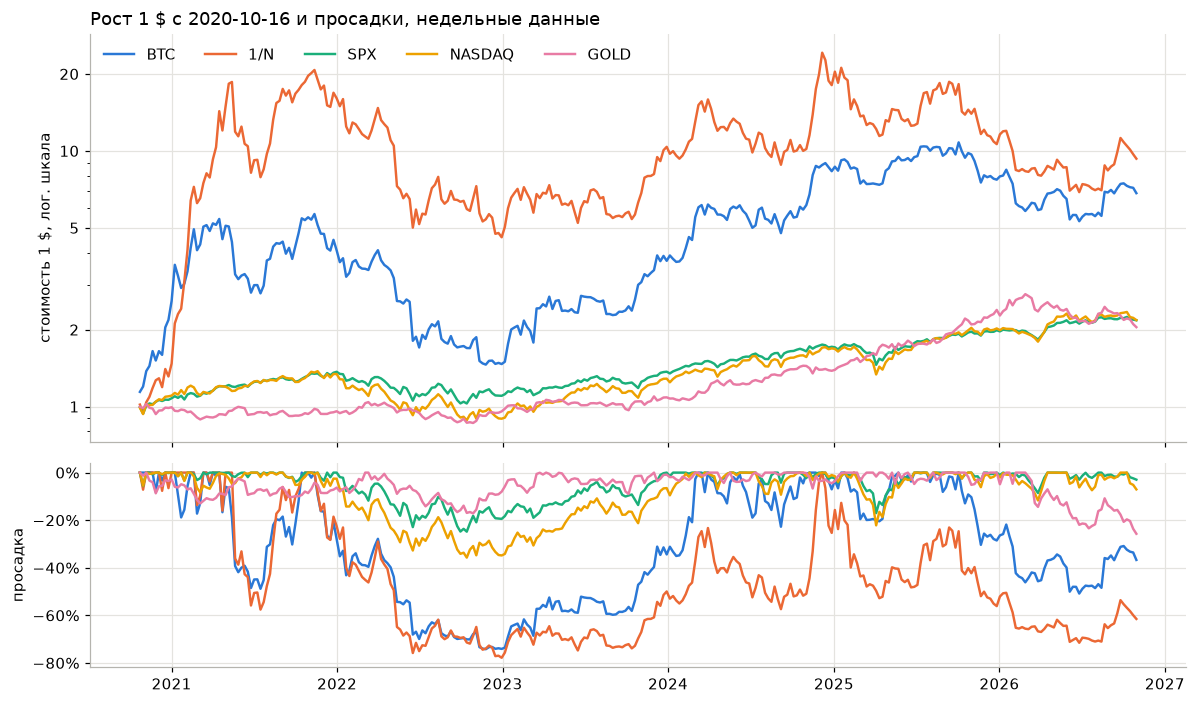

In [378]:
value = np.exp(weekly[BENCH].cumsum()).rename(columns={"EW": "1/N"})
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for i, col in enumerate(value.columns):
    ax1.plot(value[col], color=COLORS[i], label=col)
    ax2.plot(value[col] / value[col].cummax() - 1, color=COLORS[i])
ax1.set_yscale("log")
log_axis(ax1)
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax1.set_ylabel("стоимость 1 $, лог. шкала")
ax1.set_title("Рост 1 $ с 2020-10-16 и просадки, недельные данные")
ax1.legend(loc="upper left", ncol=5)
ax2.yaxis.set_major_formatter(PercentFormatter(1))
ax2.set_ylabel("просадка")
fig.tight_layout();

Доходность крипты в 2,7–3,6 раза выше, чем у индексов, волатильность в 2,9–4,8 раза выше, просадки доходили до −78% (здесь по недельным данным, по дневным они немного глубже, как в таблице раздела 2). Sharpe у всех пяти рядов от 0,72 до 0,89 (безрисковая ставка принята нулевой), а стандартная ошибка около 0,4 у каждого: при Шарпе меньше 1 она зависит в основном от длины ряда. Интервал ±2 ошибки для каждого ряда примерно от 0 до 1,7, так что по соотношению доходности и риска за этот период они статистически неразличимы. SPX здесь ценовой индекс, без дивидендов.

## 6. Капитализация и ликвидность

Капитализация (цена монеты × число монет в обращении) из Coin Metrics, объёмы из Binance. Портфель по капитализации держит монеты в долях их капитализации на предыдущий день, метрики недельные, как в разделе 5. В первые недели нет капитализации NEAR, а у POL, бывшего MATIC, при смене монеты в сентябре 2024 капитализация в источнике скачком падает и восстанавливается; на результат это почти не влияет, доля POL меньше 0,3%.

In [379]:
caps = pd.read_parquet(f"{DATA}/coinmetrics_market_caps.parquet").loc[START:END]
cap_share = caps.div(caps.sum(axis=1), axis=0)
print(f"доля BTC: {cap_share['BTC'].min():.0%}–{cap_share['BTC'].max():.0%}, сейчас {cap_share['BTC'].iloc[-1]:.0%}; "
      f"доля POL в 2024-09: до {cap_share.loc['2024-09', 'POL'].max():.2%}")

cap_w = np.log1p((cap_share.shift(1).loc[returns.index] * simple).sum(axis=1))
ports = pd.concat([cap_w.resample("W-FRI").sum().rename("по капитализации"), weekly[["EW", "BTC"]]], axis=1).loc[weekly.index].rename(columns={"EW": "1/N"})
table = ports.apply(perf).T
table["corr с BTC"] = ports.corrwith(ports["BTC"])
table.round(2)

доля BTC: 48%–80%, сейчас 72%; доля POL в 2024-09: до 0.22%


,"CAGR, %","vol, %",Sharpe,SE Sharpe,"max DD, %",corr с BTC
по капитализации,35.92,61.32,0.81,0.41,-75.29,0.97
1/N,44.74,77.01,0.85,0.41,-77.83,0.80
BTC,37.49,59.62,0.83,0.41,-74.23,1.00


Портфель по капитализации почти повторяет BTC (корреляция 0,97), отдельным бенчмарком он ничего не добавляет.

отношение объёмов BTC и ATOM: 463


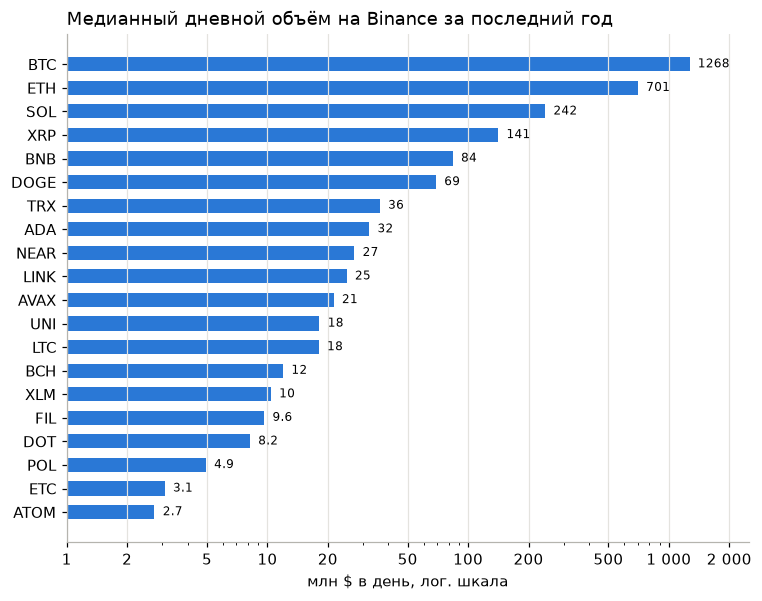

In [380]:
vol_usd = volumes.loc["2025-10-31":].median().sort_values() / 1e6
print(f"отношение объёмов BTC и {vol_usd.index[0]}: {vol_usd.iloc[-1] / vol_usd.iloc[0]:.0f}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(vol_usd.index, vol_usd.values, height=0.6)
ax.set_xscale("log")
ax.set_xlim(1, 2500)
log_axis(ax, "x")
for i, v in enumerate(vol_usd.values):
    ax.text(v * 1.1, i, f"{v:.1f}" if v < 10 else f"{v:.0f}", va="center", fontsize=8)
ax.set_xlabel("млн $ в день, лог. шкала")
ax.set_title("Медианный дневной объём на Binance за последний год")
ax.grid(axis="y", visible=False);

Объёмы различаются примерно в 460 раз, у ATOM, ETC и POL 2,7–4,9 млн $ в день. Насколько это ограничивает вес монеты, зависит от размера портфеля, который в проекте не задан.

## 7. Индикаторы и предсказуемость

Два вопроса: какие монеты обгонят остальные (кросс-секция, сравнение монет между собой на одну дату) и куда пойдёт весь рынок (тайминг).

Индикаторы посчитаны командой из дневных свечей Binance (свеча это цены открытия, максимума, минимума, закрытия и объём за день) и данных фьючерсов, индекс Fear & Greed взят с alternative.me, полные определения в README.

| Индикатор | Что измеряет |
|---|---|
| `atr_pct`, `vol_30`, `bb_width` | волатильность монеты: средний дневной диапазон цены, std доходности за 30 дней, ширина полос Боллинджера |
| `mom_7`, `mom_30`, `mom_90` | моментум, доходность за прошлые 7, 30, 90 дней |
| `rsi_14`, `stoch_k`, `stoch_d`, `mfi_14` | насколько монета «перекуплена» или «перепродана» за 14 дней, шкала 0–100 |
| `macd_*` | разница быстрой и медленной скользящих средних цены |
| `bb_pctb`, `dist_sma50`, `dist_sma200` | где цена относительно своих средних |
| `volume_z_30` | всплеск объёма торгов относительно 30 прошлых дней |
| `funding_rate`, `funding_premium*` | фандинг, плата между держателями ставок на рост и на падение в бессрочных фьючерсах (высокий фандинг означает перекос в ставки на рост), и его часть сверх стандартной ставки Binance |
| `fng` | индекс страха и жадности Fear & Greed для всего рынка, 0–100 |
| `breadth_*`, `share_overbought`, `share_oversold` | доли монет выше своих средних и с крайними значениями RSI |
| `altseason_90`, `corr_30_mean`, `vol_30_mean` | доля альткоинов, обогнавших BTC за 90 дней, средние корреляция и волатильность монет |

Для кросс-секции считается IC (information coefficient), ранговая корреляция Спирмена между индикатором на день D и суммой дневных доходностей $r_t$ за дни D+1…D+h по 20 монетам. Даты взяты с шагом h, чтобы периоды не пересекались, $t = \overline{IC} / \sigma_{IC} \cdot \sqrt{n}$, где n число дат. Проверок 20 индикаторов × 3 горизонта = 60, поэтому порог значимости берём с поправкой Бонферрони.

In [381]:
ind = pd.read_parquet(f"{DATA}/filled/indicators.parquet")
FEATS = [c for c in ind.columns if c not in ("date", "coin")]
wide = {f: ind.pivot(index="date", columns="coin", values=f).loc[START:END, COINS] for f in FEATS}


def forward(r, h):
    # сумма доходностей за следующие h дней
    return r[::-1].rolling(h).sum()[::-1].shift(-1)


def ic_series(feature, h):
    dates = returns.index[::h]
    x = wide[feature].loc[dates].rank(axis=1)
    y = forward(returns, h).loc[dates].rank(axis=1)
    return x.corrwith(y, axis=1).dropna()


rows = {}
for f in FEATS:
    for h in (1, 7, 30):
        ic = ic_series(f, h)
        rows[f, h] = {"IC": ic.mean(), "t": ic.mean() / ic.std() * np.sqrt(len(ic))}
ic_table = pd.DataFrame(rows).T.unstack()
ic_table.columns = [f"{m}, {h}д" for m, h in ic_table.columns]
T_BONF = NormalDist().inv_cdf(1 - 0.025 / 60)
print(f"порог |t| с поправкой Бонферрони на 60 проверок: {T_BONF:.2f}")
ic_table.sort_values("t, 7д").round({c: 3 if c.startswith("IC") else 1 for c in ic_table.columns})

порог |t| с поправкой Бонферрони на 60 проверок: 3.34


,"IC, 1д","IC, 7д","IC, 30д","t, 1д","t, 7д","t, 30д"
atr_pct,-0.073,-0.114,-0.154,-9.0,-5.6,-3.8
vol_30,-0.068,-0.100,-0.121,-8.8,-5.2,-3.3
bb_width,-0.053,-0.066,-0.060,-7.1,-3.6,-1.6
funding_rate,-0.027,-0.034,-0.020,-5.1,-2.5,-0.7
funding_premium_7,-0.015,-0.012,-0.016,-2.8,-0.8,-0.5
mom_7,-0.025,-0.013,-0.021,-3.9,-0.8,-0.7
funding_premium,-0.016,-0.009,0.006,-3.1,-0.7,0.2
mom_30,-0.016,-0.007,-0.022,-2.4,-0.4,-0.7
dist_sma50,-0.020,-0.005,-0.021,-3.1,-0.3,-0.7
mfi_14,-0.026,-0.004,-0.032,-4.6,-0.3,-1.1


На горизонте 7 дней поправку проходят только индикаторы волатильности (`atr_pct`, `vol_30`, `bb_width`): более волатильные монеты в следующие дни чаще оказываются внизу рейтинга по доходности. `funding_rate` (t = −2,5) поправку не проходит. У моментума, RSI и MACD на 7 и 30 днях IC около нуля. На горизонте 1 день отрицательный IC проходит поправку у многих индикаторов. У `mom_7`, `macd_hist_pct` и `mfi_14` это значит, что монеты, сильнее выросшие за последние дни, на следующий день в среднем немного отстают. Так же ведут себя монеты со всплеском объёма (`volume_z_30`) и с высоким фандингом (`funding_rate`). Это разворот на один день. Использовать его можно только при ежедневной ребалансировке с большим оборотом и комиссиями, в план следующего этапа с недельной ребалансировкой он не входит.

Стабильность по годам (h = 7):

In [382]:
pd.DataFrame({f: (lambda ic: ic.groupby(ic.index.year).mean())(ic_series(f, 7))
              for f in ["atr_pct", "vol_30", "bb_width"]}).T.round(3)

date,2020,2021,2022,2023,2024,2025,2026
atr_pct,-0.257,-0.014,-0.140,-0.092,-0.099,-0.199,-0.114
vol_30,-0.129,-0.029,-0.112,-0.084,-0.084,-0.168,-0.120
bb_width,-0.052,0.005,-0.080,-0.075,-0.040,-0.124,-0.094


IC индикаторов волатильности отрицательный каждый год, в 2021 году близок к нулю.

Недельная доходность по квинтилям `atr_pct`, в первом квинтиле самые спокойные монеты. Разница пятого и первого квинтиля посчитана по каждой дате отдельно, t по этим разницам.

In [383]:
dates = returns.index[::7]
quint = wide["atr_pct"].loc[dates].rank(axis=1, pct=True).stack()
quint = pd.cut(quint, [0, 0.2, 0.4, 0.6, 0.8, 1], labels=[1, 2, 3, 4, 5])
fwd7 = forward(returns, 7).loc[dates].stack()

by_q = pd.DataFrame({
    "медиана лог-доходности, %": fwd7.groupby(quint).median() * 100,
    "среднее лог-доходности, %": fwd7.groupby(quint).mean() * 100,
    "среднее обычной доходности, %": np.expm1(fwd7).groupby(quint).mean() * 100,
}).T
frame = pd.DataFrame({"q": quint, "log": fwd7, "simple": np.expm1(fwd7)}).dropna()
per_date = frame.groupby([frame.index.get_level_values(0), "q"], observed=True)[["log", "simple"]].mean().unstack("q")
for kind in ["log", "simple"]:
    spread = per_date[(kind, 5)] - per_date[(kind, 1)]
    by_q.loc[f"t разницы 5−1, {kind}", 1] = spread.mean() / spread.std() * np.sqrt(len(spread))
by_q.round(2)

,1,2,3,4,5
"медиана лог-доходности, %",0.31,-0.52,-0.56,-0.77,-1.50
"среднее лог-доходности, %",0.80,0.30,0.30,0.36,-0.20
"среднее обычной доходности, %",1.34,1.15,1.38,1.67,1.03
"t разницы 5−1, log",-2.11,NaN,NaN,NaN,NaN
"t разницы 5−1, simple",-0.60,NaN,NaN,NaN,NaN


По медиане самые волатильные монеты отстают от самых спокойных на 1,8 п.п. в неделю, по среднему лог-доходности на 1,0 п.п. (t = −2,1). По среднему обычной доходности разницы почти нет: 1,0% против 1,3% в неделю, t = −0,6. Причина та же, что в примере +50% и −50%: волатильные монеты чаще теряют, но редкие большие скачки возвращают среднее. Портфель зарабатывает обычную доходность, поэтому для отбора монет сигнал почти бесполезен, он описывает риск. При этом методы, которые подбирают веса по риску (минимальная дисперсия, обратная волатильность), сами дают меньше веса волатильным монетам, и это нужно учитывать при чтении их результатов.

### Проверка моделью

Поиндикаторный IC ловит только простые связи с одним признаком. Проверим, найдёт ли модель сигнал в комбинации всех 20 индикаторов. Градиентный бустинг (ансамбль деревьев решений) обучается на всех монетах сразу на признаках дня D. Целей две: сумма доходностей за D+1…D+7 и логарифм std дневных доходностей за те же 7 дней.

Проверка walk-forward по годам: модель для года Y учится только на данных до Y, последние 7 дней перед Y выброшены, чтобы цели обучения не заходили в тестовый год. R² вне выборки меньше нуля означает, что модель хуже простого прогноза средним по прошлым данным. IC здесь средняя по дням ранговая корреляция прогноза с фактом по 20 монетам.

Для сравнения два простых прогноза. Для доходности IC одного признака `−vol_30`. Для волатильности прошлая `vol_30`, приведённая к шкале цели линейной регрессией на обучающих данных.

scikit-learn в зависимости проекта не входит, ставится командой `uv pip install scikit-learn`.

In [384]:
from sklearn.ensemble import HistGradientBoostingRegressor

H = 7
panel = ind[ind["coin"].isin(COINS)].set_index(["date", "coin"]).sort_index().loc[returns.index[0]:returns.index[-1]]
y_ret = forward(returns, H).stack()
y_vol = np.log(returns[::-1].rolling(H).std()[::-1].shift(-1).stack())
y_ret.index.names = y_vol.index.names = ["date", "coin"]
panel = panel.join(y_ret.rename("y_ret")).join(y_vol.rename("y_vol")).dropna()
panel["year"] = panel.index.get_level_values("date").year
panel["naive_vol"] = np.log(panel["vol_30"] / np.sqrt(365))   # vol_30 годовая, цель дневная


def walk_forward(target, naive=None):
    rows = {}
    for year in range(2022, 2027):
        test = panel[panel["year"] == year]
        cutoff = test.index.get_level_values("date").min() - pd.Timedelta(days=H + 1)
        train = panel[panel.index.get_level_values("date") <= cutoff]
        model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.03, max_depth=4, min_samples_leaf=200,
                                              early_stopping=False, random_state=0)
        model.fit(train[FEATS], train[target])
        pred = pd.Series(model.predict(test[FEATS]), index=test.index)
        y = test[target]
        base = train[target].mean()
        r2 = lambda p: 1 - ((y - p) ** 2).sum() / ((y - base) ** 2).sum()
        ic = lambda p: pd.DataFrame({"p": p, "y": y}).groupby(level="date").apply(lambda g: g["p"].corr(g["y"], method="spearman")).mean()
        rows[year] = {"R² вне выборки": r2(pred), "IC": ic(pred)}
        if naive is None:
            rows[year]["IC −vol_30"] = ic(-test["vol_30"])
        else:
            b, a = np.polyfit(train[naive], train[target], 1)
            rows[year]["R² простого"] = r2(a + b * test[naive])
            rows[year]["IC простого"] = ic(test[naive])
    return pd.DataFrame(rows).T


ml = pd.concat({"доходность за 7 дней": walk_forward("y_ret"), "волатильность за 7 дней": walk_forward("y_vol", naive="naive_vol")}, axis=1)
ml.round(3)

доходность за 7 дней                   волатильность за 7 дней         \
           R² вне выборки     IC IC −vol_30          R² вне выборки     IC   
2022               -0.103 -0.008      0.122                   0.317  0.456   
2023               -0.089  0.005      0.064                   0.550  0.505   
2024               -0.032  0.011      0.067                   0.391  0.590   
2025                0.017  0.098      0.161                   0.236  0.567   
2026               -0.034  0.069      0.122                   0.462  0.550   

                              
     R² простого IC простого  
2022       0.265       0.562  
2023       0.496       0.547  
2024       0.274       0.564  
2025       0.228       0.520  
2026       0.432       0.518

Доходность: R² вне выборки от −0,10 до +0,02, модель обыграла прогноз средним только в 2025 году и на 0,02. IC бустинга от −0,01 до 0,10, у одного признака `−vol_30` от 0,06 до 0,16: двадцать признаков ранжируют монеты хуже, чем одна волатильность. Предсказать доходность модель не смогла.

Волатильность: R² от 0,24 до 0,55, у простого прогноза 0,23–0,50, бустинг выше каждый год на 0,01–0,12. Часть R² даёт угаданный общий уровень волатильности в тестовом году, а для весов портфеля важнее, как прогноз ранжирует монеты по будущему риску. По этому критерию модель почти не отличается от простого прогноза: IC бустинга 0,46–0,59, у прошлой `vol_30` 0,52–0,56; в 2022–2023 годах простой прогноз лучше, в 2024–2026 годах бустинг немного лучше. Почти весь сигнал о риске даёт прошлая волатильность монеты. Гиперпараметры не подбирались, это проверка наличия сигнала.

### Тайминг рынка

Корреляция общерыночных индикаторов с доходностью и волатильностью портфеля 1/N за следующие 30 дней (непересекающиеся окна, n ≈ 73).

In [385]:
mkt = pd.read_parquet(f"{DATA}/filled/market_indicators.parquet").loc[START:END]
ew = np.log1p(simple.mean(axis=1))
idx = returns.index[::30]
target = pd.DataFrame({
    "ret": forward(ew, 30).loc[idx],
    "vol": ew[::-1].rolling(30).std()[::-1].shift(-1).loc[idx],
})

rows = {}
for c in mkt.columns:
    d = pd.concat([mkt[c].loc[idx].rename("x"), target], axis=1).dropna()
    half = len(d) // 2
    rows[c] = {
        "corr с доходностью": d["x"].corr(d["ret"]),
        "1-я половина": d["x"].iloc[:half].corr(d["ret"].iloc[:half]),
        "2-я половина": d["x"].iloc[half:].corr(d["ret"].iloc[half:]),
        "corr с волатильностью": d["x"].corr(d["vol"]),
        "vol, 1-я половина": d["x"].iloc[:half].corr(d["vol"].iloc[:half]),
        "vol, 2-я половина": d["x"].iloc[half:].corr(d["vol"].iloc[half:]),
    }
print(f"n = {len(d)}, порог значимости корреляции 2/√n = {2 / np.sqrt(len(d)):.2f}, с поправкой Бонферрони на {len(mkt.columns)} индикаторов {NormalDist().inv_cdf(1 - 0.025 / len(mkt.columns)) / np.sqrt(len(d)):.2f}")
pd.DataFrame(rows).T.sort_values("corr с доходностью").round(2)

n = 73, порог значимости корреляции 2/√n = 0.23, с поправкой Бонферрони на 13 индикаторов 0.34


,corr с доходностью,1-я половина,2-я половина,corr с волатильностью,"vol, 1-я половина","vol, 2-я половина"
corr_30_mean,-0.21,-0.24,-0.18,-0.21,-0.34,-0.06
altseason_90,-0.14,-0.15,-0.15,0.36,0.38,0.22
share_oversold,-0.01,-0.14,0.42,0.11,0.11,-0.10
breadth_sma50,0.05,0.11,-0.03,0.21,0.33,0.11
vol_30_mean,0.06,0.13,-0.27,0.61,0.59,0.37
rsi_mean,0.09,0.18,-0.04,0.18,0.21,0.20
share_overbought,0.11,0.17,0.04,0.21,0.23,0.26
btc_vol_30,0.11,0.16,-0.08,0.40,0.38,0.00
breadth_sma200,0.14,0.26,-0.03,0.34,0.35,0.41
funding_premium_mean,0.21,0.24,0.02,0.25,0.20,0.28


При 73 точках порог значимости корреляции 0,23, с поправкой на 13 индикаторов 0,34. Для доходности следующего месяца поправку не проходит ни один индикатор, то есть сигнал о направлении рынка не обнаружен (при 73 точках найти можно только корреляции больше 0,34). Самые высокие корреляции у Fear & Greed (0,31) и фандинга BTC (0,29), во второй половине периода они падают до 0,05–0,10, у `share_oversold` меняется знак. С волатильностью следующего месяца связь сильнее: у `vol_30_mean` 0,61 (0,59 и 0,37 по половинам), у `btc_funding_premium` и `breadth_sma200` около 0,35 в обеих половинах.

### Новости и внимание к монете

Проверка идеи команды добавить новости или интерес публики как признак. Liu и Tsyvinski (2021) на данных 2011–2018 нашли, что рост поисковых запросов «Bitcoin» в Google предсказывает доходность биткоина на одну-две недели вперёд. Проверяем похожую связь на нашем периоде. Google Trends отдаёт индекс запросов от 0 до 100, где 100 пик за период; запрос на 5 лет возвращает недели, на 8 месяцев дни. Мера внимания у нас проще, чем в статье: недельное изменение индекса.

Данные запрашиваются при запуске ячейки библиотекой pytrends (ставится командой `uv pip install pytrends`). Google ограничивает частоту запросов (ошибка 429, нужно подождать несколько минут), а индекс строится по выборке запросов и при повторной выгрузке немного меняется, поэтому числа ниже даны с округлением. Неделя у Google начинается в воскресенье, ценовая неделя взята с воскресенья по субботу.

In [386]:
import time
from pytrends.request import TrendReq

pt = TrendReq(hl="en-US", tz=0, timeout=(10, 30))
trends = {}
for kw, timeframe, name in [
    ("bitcoin", "2021-11-01 2026-10-30", "btc_weekly"),
    ("solana", "2021-11-01 2026-10-30", "sol_weekly"),
    ("bitcoin", "2026-03-01 2026-10-30", "btc_daily"),
]:
    pt.build_payload([kw], timeframe=timeframe)
    trends[name] = pt.interest_over_time()[kw]
    time.sleep(5)
print({k: (len(v), f"{v.index.min():%Y-%m-%d} – {v.index.max():%Y-%m-%d}") for k, v in trends.items()})

p_naive = p_filled.copy()
p_naive.index = p_naive.index.tz_localize(None)


def align_weekly(coin, series):
    wp = p_naive[coin].resample("W-SAT").last()
    wp.index = wp.index - pd.Timedelta(days=6)
    return np.log(wp).diff().reindex(series.index), np.log(series).diff(), series


def lead_lag(r, d_trends, level, lags=range(-2, 3)):
    # k < 0: тренды за |k| периодов до доходности (опережение), k > 0: после
    return pd.DataFrame({
        f"{k:+d} ({'тренды раньше' if k < 0 else 'тренды позже' if k > 0 else 'одновременно'})": {
            "corr(r, Δtrends)": r.corr(d_trends.shift(-k)),
            "corr(|r|, Δtrends)": r.abs().corr(d_trends.shift(-k)),
            "corr(|r|, уровень)": r.abs().corr(level.shift(-k)),
        } for k in lags
    })


r_w, dt_w, lvl_w = align_weekly("BTC", trends["btc_weekly"])
r_s, dt_s, lvl_s = align_weekly("SOL", trends["sol_weekly"])
r_d = np.log(p_naive["BTC"]).diff().reindex(trends["btc_daily"].index)
dt_d = np.log(trends["btc_daily"]).diff()

pd.concat({
    "BTC, недели": lead_lag(r_w, dt_w, lvl_w),
    "SOL, недели": lead_lag(r_s, dt_s, lvl_s),
    "BTC, дни": lead_lag(r_d, dt_d, trends["btc_daily"]),
}).round(2)

{'btc_weekly': (261, '2021-10-31 – 2026-10-25'), 'sol_weekly': (261, '2021-10-31 – 2026-10-25'), 'btc_daily': (244, '2026-03-01 – 2026-10-30')}


-2 (тренды раньше)  -1 (тренды раньше)  \
BTC, недели corr(r, Δtrends)                  0.03                0.07   
            corr(|r|, Δtrends)                0.01                0.03   
            corr(|r|, уровень)               -0.05               -0.03   
SOL, недели corr(r, Δtrends)                  0.09                0.03   
            corr(|r|, Δtrends)                0.19                0.10   
            corr(|r|, уровень)               -0.11               -0.09   
BTC, дни    corr(r, Δtrends)                  0.05               -0.03   
            corr(|r|, Δtrends)                0.10                0.11   
            corr(|r|, уровень)                0.18                0.25   

                                +0 (одновременно)  +1 (тренды позже)  \
BTC, недели corr(r, Δtrends)                -0.10              -0.01   
            corr(|r|, Δtrends)               0.56               0.01   
            corr(|r|, уровень)               0.36               0.35   
SOL, недели corr(r, Δtrends)                 0.09               0.22   
            corr(|r|, Δtrends)               0.42              -0.01   
            corr(|r|, уровень)               0.03               0.05   
BTC, дни    corr(r, Δtrends)                 0.10              -0.05   
            corr(|r|, Δtrends)               0.24              -0.06   
            corr(|r|, уровень)               0.40               0.34   

                                +2 (тренды позже)  
BTC, недели corr(r, Δtrends)                 0.09  
            corr(|r|, Δtrends)              -0.19  
            corr(|r|, уровень)               0.18  
SOL, недели corr(r, Δtrends)                 0.01  
            corr(|r|, Δtrends)              -0.24  
            corr(|r|, уровень)              -0.02  
BTC, дни    corr(r, Δtrends)                -0.05  
            corr(|r|, Δtrends)              -0.21  
            corr(|r|, уровень)               0.24

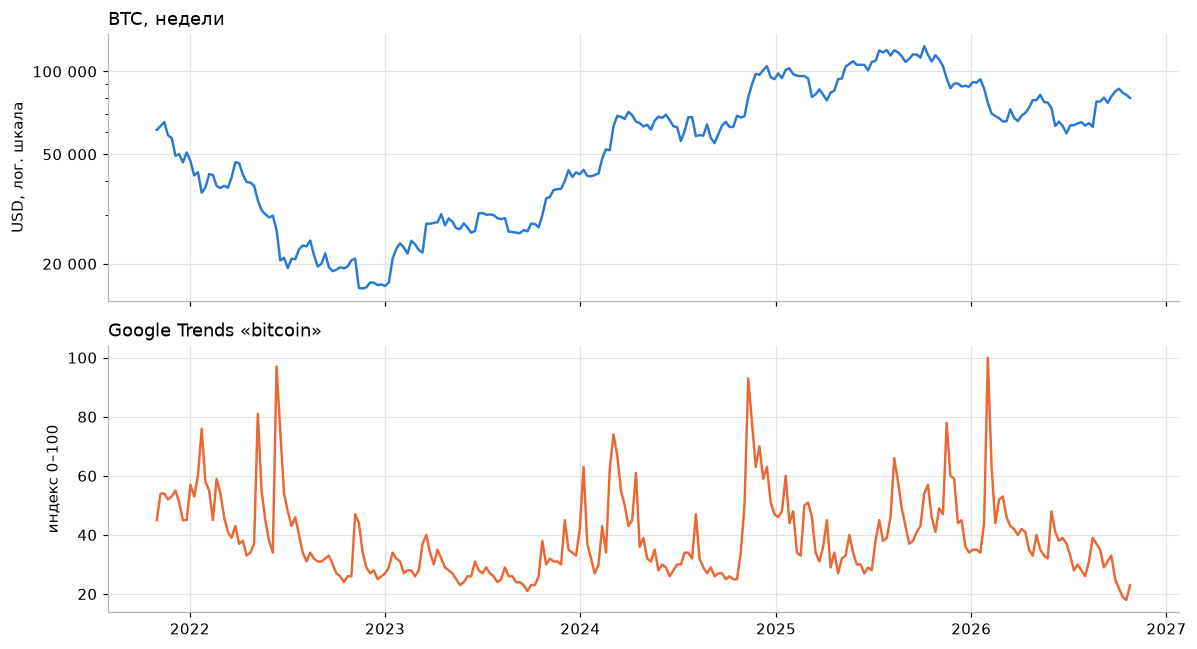

In [387]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.plot(p_naive["BTC"].reindex(lvl_w.index, method="nearest"), color=COLORS[0])
ax1.set_yscale("log")
log_axis(ax1)
ax1.set_ylabel("USD, лог. шкала")
ax1.set_title("BTC, недели")
ax2.plot(lvl_w, color=COLORS[1])
ax2.set_ylabel("индекс 0–100")
ax2.set_title("Google Trends «bitcoin»")
fig.tight_layout();

Интерес растёт одновременно с размахом движения цены в любую сторону: корреляция изменения интереса с модулем доходности того же периода около 0,55 у BTC по неделям, около 0,4 у SOL, около 0,23 у BTC по дням. До движения изменение интереса у BTC почти ничего не говорит (0,02–0,04 по неделям, около 0,1 по дням при пороге значимости 0,12–0,13). У SOL за две недели до движения 0,18, но среди 45 корреляций таблицы одна такая может оказаться случайной. Пики индекса совпадают с крупными движениями: июнь 2022, ноябрь 2024, февраль 2026. Почему результат расходится со статьёй, точно не известно; возможно, с приходом фондов и биржевых фондов на биткоин интерес публики стал откликом на движение.

Новости и внимание как признак не берём: опережающей связи с доходностью нет, а для волатильности прирост к прошлой волатильности не показан. Тексты новостей с оценкой тональности тем более не рассматриваем: для них нужен источник с шестилетней историей, точным временем публикации и защитой от утечки будущего.

## 8. Выводы для портфеля

### Главное

1. Данные надёжны: медианное расхождение цен Binance с независимым источником 0,1–0,2%. Но набор монет выбран задним числом, из монет, которые торгуются в 2026 году, поэтому любая проверка стратегии на истории завысит её доходность, сильнее всего у стратегий с большой долей альткоинов.
2. Какая монета в среднем растёт быстрее, по шести годам истории сказать нельзя: средние доходности неотличимы от случайного шума. Методы, которым нужен прогноз доходности (классический Марковиц), будут подстраиваться под этот шум.
3. Риск, наоборот, предсказуем: бурные периоды тянутся неделями, волатильность прошлого месяца хорошо говорит о следующем. Веса портфеля разумно подбирать по риску.
4. Резкие движения цены (в обе стороны) случаются в 4–8 раз чаще, чем предсказывает нормальное распределение. Кроме волатильности нужно смотреть на средний убыток в худшие дни (CVaR) и на просадки.
5. Монеты движутся почти вместе: общее движение рынка объясняет 62% колебаний, а в дни резкого падения BTC монеты синхроннее, чем в дни резкого роста (корреляция 0,62 против 0,34). Разложить деньги по 20 монетам почти не спасает при обвале.
6. Технические индикаторы и модель машинного обучения не предсказывают, какая монета обгонит остальные на горизонте недели и больше, а поиск в Google не предсказывает доходность BTC и SOL. Сигнал есть только о риске, и почти весь его даёт прошлая волатильность монеты.
7. Отсюда план следующего этапа: основные кандидаты это портфели, которые распределяют риск (минимальная дисперсия, risk parity, HRP, минимальный CVaR), прогноз риска моделью как эксперимент, классический Марковиц как контроль.

### Какие стратегии тестируем

Доходности по истории не оцениваются, риск оценивается, поэтому основные кандидаты это методы, которым нужна только ковариационная матрица Σ (дисперсии монет и ковариации между ними). Классический Марковиц нужен как контроль: он показывает, сколько теряется, когда в оптимизацию подставляют шумные средние.

| Стратегия | Что нужно на вход | Кому даёт больше веса | Почему из анализа |
|---|---|---|---|
| BTC, 1/N | ничего | одной монете / всем поровну | бенчмарки; портфель по капитализации почти совпадает с BTC (раздел 6) |
| Марковиц, максимум Шарпа | средние доходности и Σ | монетам с высокой прошлой доходностью | контроль: средние неотличимы от шума (раздел 2; Chopra, Ziemba, 1993; DeMiguel и др., 2009) |
| Минимальная дисперсия | Σ | наименее волатильным: TRX, BTC, BNB | риск прогнозируется (раздел 3) |
| Обратная волатильность | волатильности монет | вес ∝ 1/σ, меньше всего NEAR, AVAX, FIL | альткоины в 1,3–2,1 раза волатильнее BTC (раздел 3) |
| Risk parity | Σ | так, чтобы каждая монета давала одинаковый вклад в риск портфеля (Maillard и др., 2010) | то же, с учётом корреляций |
| HRP | Σ | делит капитал по дереву похожих монет, без обращения Σ (López de Prado, 2016) | один сильный фактор плюс группы монет (раздел 4) |
| Минимальный CVaR | история доходностей | монетам с меньшими потерями в худшие дни (Rockafellar, Uryasev, 2000) | тяжёлые хвосты, синхронные падения (разделы 2, 4) |
| Те же методы с ML-прогнозом риска (эксперимент) | прогноз волатильности моделью | как исходный метод | бустинг точнее простого прогноза по уровню волатильности, но ранжирует монеты почти так же (раздел 7) |

Без ограничений минимальная дисперсия сосредоточится в нескольких наименее волатильных монетах, поэтому вес одной монеты ограничиваем. Σ берём по скользящему окну и сглаживаем методом Ледуа–Вольфа (Ledoit, Wolf, 2004): выборочная матрица по нескольким месяцам для 20 монет шумная, а сглаживание смешивает её с более простой, например с матрицей одинаковых корреляций.

Машинное обучение для прогноза риска остаётся экспериментом: в разделе 7 бустинг точнее простого прогноза по общему уровню волатильности, а по ранжированию монет почти не отличается от прошлой волатильности за 30 дней. Бэктест покажет, даёт ли модель лучший портфель, чем простое скользящее окно. Корреляции между монетами моделью не прогнозировались, их берём по скользящему окну. Выделение режимов рынка по волатильности и корреляциям и выбор стратегии многоруким бандитом (алгоритм, который постепенно отдаёт предпочтение стратегиям, работавшим лучше в последнее время) можно попробовать как эксперимент: анализ данных их прямо не обосновывает, а крупных рыночных циклов за период всего несколько.

Не тестируем отбор монет по моментуму, RSI, MACD и другим техническим индикаторам: на горизонте 7–30 дней их связь с будущей доходностью не обнаружена, а однодневный разворот требует ежедневной ребалансировки. На широкой выборке из примерно 1700 монет моментум найден (Liu, Tsyvinski, Wu, 2022), но наши 20 крупных монет с одним общим фактором для таких эффектов слишком узкая выборка. Новости и интерес в Google тоже не берём (раздел 7).

### Что добавить в постановку

Стейблкоин как актив. Без денежной позиции любая стратегия может только перекладывать капитал между монетами, которые падают вместе. С USDT как 21-м активом с нулевой доходностью появляется возможность управлять общим уровнем риска: держать часть капитала в USDT постоянно или уменьшать долю крипты в бурные периоды. На рынке акций второй способ повышал Шарп (Moreira, Muir, 2017), но устойчивость эффекта оспаривается (Cederburg и др., 2020), а в разделе 3 признаков того, что в бурные периоды крипта даёт меньше доходности на единицу риска, нет. Поэтому сравнивать его нужно с постоянной долей USDT. Новых данных не нужно, ряд USDT это нули

Пятиминутные свечи. Сейчас волатильность оценивается по дневным доходностям, за месяц это 30 точек. Волатильность по пятиминутным изменениям цены внутри дня (реализованная волатильность) опирается на 288 точек в день, шумит заметно меньше и хорошо прогнозируется (Andersen и др., 2003; Liu, Patton, Sheppard, 2015). Это главный кандидат в признаки для ML-прогноза риска. Загрузчик проекта сейчас берёт только дневные свечи, ему нужен параметр интервала.

### Как сравниваем

Бенчмарки: BTC, 1/N с теми же правилами ребалансировки и комиссиями, что у стратегий, S&P 500 и золото. Веса на день D считаются только по данным до D и применяются со следующего дня. Ребалансировка раз в неделю: волатильность держится неделями, недельного пересчёта хватает, чтобы за ней успевать. Комиссия 0,1% от оборота (обычная комиссия Binance), без коротких продаж (отрицательных весов), вес одной монеты не больше 25% с проверкой 20% и 30%.

Смотрим CAGR, волатильность, Шарп, CVaR 5% по дневным доходностям, максимальную просадку и оборот, по всему периоду и отдельно по фазам рынка. Стандартная ошибка Шарпа за 6 лет около 0,4, а внутри фазы ещё больше, поэтому разницу Шарпов двух стратегий проверяем специальным парным тестом (Ledoit, Wolf, 2008), а на риск-метрики, которые оцениваются точнее, смотрим в первую очередь. Окна, параметры и лимиты фиксируем до запуска бэктеста. Анализ данных и бэктест делаются на одном и том же периоде, поэтому бэктест покажет, какие стратегии лучше на этой истории, но не будет независимой проверкой на новых данных.